In [58]:
# Random Forest Implementation
import pandas as pd
import sklearn
import numpy as np
import scipy
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
import scipy.stats as stats
import seaborn as sns
from matplotlib.patches import Patch

In [2]:
df = pd.read_csv("results/assignment3/affinity/sorted_genes.csv")
df

,Gene,SRR2534402,SRR2534403,SRR2534404,SRR2534405,SRR2534406,SRR2534407,SRR2534408,SRR2534409,SRR2534410,...,SRR2535038,SRR2535039,SRR2535040,SRR2535041,SRR2535042,SRR2535043,SRR2535044,SRR2535045,SRR2535046,SRR2535047
0,Lars2,18.686778,17.942373,19.279816,19.727014,20.043443,18.466178,19.021748,18.138422,90.305486,...,11.997342,11.445452,9.899983,8.863214,9.204295,9.155986,10.286630,8.943861,9.934873,9.645423
1,Mir6236,40.008331,40.724974,41.262309,41.580819,40.355943,40.469911,40.285823,41.452146,80.438028,...,35.227715,34.002301,41.843580,42.504179,41.085445,42.238744,41.326141,41.961827,41.514807,41.713337
2,Mup15,85.497160,84.877921,84.382044,85.497160,85.497160,84.877921,84.877921,85.497160,76.617575,...,80.001721,79.282446,98.170073,98.170073,97.362222,98.170073,97.362222,97.362222,98.170073,99.066884
3,Mup17,74.490667,75.350819,75.050092,75.050092,74.749365,75.050092,75.350819,74.749365,71.182024,...,77.984974,76.954759,93.417512,94.029779,93.417512,94.029779,93.417512,94.029779,94.029779,93.417512
4,Grip2,57.645500,47.460108,29.807702,28.382645,39.775930,29.680578,33.569053,24.718278,52.866789,...,59.079150,67.010969,58.625124,55.672795,39.645982,43.867946,46.822504,42.238744,45.647330,53.196817
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37766,Krtap2-21,0.236804,0.236517,0.237815,0.237395,0.234727,0.236399,0.236287,0.237697,0.231434,...,0.219176,0.219518,0.224586,0.221831,0.225496,0.222731,0.222293,0.225023,0.221662,0.225210
37767,Or1o2,0.236804,0.236517,0.237815,0.237395,0.234727,0.236399,0.236287,0.237697,0.231434,...,0.219176,0.219518,0.224586,0.221831,0.225496,0.222731,0.222293,0.225023,0.221662,0.225210
37768,Gm15290,0.236804,0.236517,0.237815,0.237395,0.234727,0.236399,0.236287,0.237697,0.231434,...,0.219176,0.219518,0.224586,0.221831,0.225496,0.222731,0.222293,0.225023,0.221662,0.225210
37769,Vmn2r51,0.236804,0.236517,0.237815,0.237395,0.234727,0.236399,0.236287,0.237697,0.231434,...,0.219176,0.219518,0.224586,0.221831,0.225496,0.222731,0.222293,0.225023,0.221662,0.225210


In [3]:
# Make a list for the experiment labels
hierarchical_results = pd.read_csv("results/assignment3/hierarchical/cluster_labels.csv")
sample_groups = []
for sample in hierarchical_results["sample_id"]:
    sample_groups.append(int(sample[3:]) <= 2534782) # True means in AL group

In [4]:
'''
I chose to work with this one because it has 11 clusters. With only 500 data points, more clusters would yield a worse model.
'''
cluster_labels_affinity = pd.read_csv("results/assignment3/affinity/cluster_results.csv")["5000_genes_-10000_Preference"]

In [5]:
X = df.drop(columns='Gene')[:5000].T.to_numpy() # Becomes a 2d array for input
clf = make_pipeline(StandardScaler(), RandomForestClassifier(max_depth=5, random_state=42))

# getting labels and probabilities from random forest
cv = StratifiedKFold(5, shuffle=True, random_state=42)
labels = cross_val_predict(clf, X, sample_groups, cv=cv)
probs  = cross_val_predict(clf, X, sample_groups, cv=cv, method="predict_proba")
roc_auc_score(sample_groups, probs[:, 1])

1.0

In [6]:
labels_cluster = cross_val_predict(clf, X, cluster_labels_affinity, cv=cv)
probs_cluster = cross_val_predict(clf, X, cluster_labels_affinity, cv=cv, method="predict_proba")
roc_auc_score(cluster_labels_affinity, probs_cluster, multi_class="ovr")

0.9994965377731344

In [7]:
# how gene count affects ROC
gene_counts = [10, 100, 1000, 10000]
print("Experimental Labels:")
for gc in gene_counts:
    X = df.drop(columns='Gene')[:gc].T.to_numpy()
    probs  = cross_val_predict(clf, X, sample_groups, cv=cv, method="predict_proba")
    print("Gene Count:", gc, "| AUC:", roc_auc_score(sample_groups, probs[:, 1]))

print("Cluster Labels")
for gc in gene_counts:
    X = df.drop(columns='Gene')[:gc].T.to_numpy()
    probs_cluster = cross_val_predict(clf, X, cluster_labels_affinity, cv=cv, method="predict_proba")
    print("Gene Count:", gc, "| AUC:", roc_auc_score(cluster_labels_affinity, probs_cluster, multi_class="ovr"))


Experimental Labels:
Gene Count: 10 | AUC: 0.9982037660024661
Gene Count: 100 | AUC: 1.0
Gene Count: 1000 | AUC: 1.0
Gene Count: 10000 | AUC: 1.0
Cluster Labels
Gene Count: 10 | AUC: 0.998453467476351
Gene Count: 100 | AUC: 0.9996425678754708
Gene Count: 1000 | AUC: 0.9995609984458295
Gene Count: 10000 | AUC: 0.9996373382682674


In [41]:
# Part 3
# confused on #3b since "cluster 1" in each model means something different,
# interpreting as "how many models correctly predict cluster"

results_RF = [labels, labels_cluster, cluster_labels_affinity]
results_Logistic = pd.read_csv("results/assignment4/logistic_results.csv").to_numpy()
results_knn = pd.read_csv("results/assignment4/knn_results.csv").to_numpy()

model_label_matrix = []
correct_label_counts = []
correct_cluster_counts = []
# loop thru each sample, count correct label fraction
for i in range(len(labels)):
    # Order: True Experiment Label, True Affinity Cluster, True Hierarchical Cluster, 
    # True Kmeans Cluster, RF Predicted Label, RF Predicted Affinity Cluster, LR Predicted Label,
    # LR Predicted Hierarchical Cluster, KNN Predicted Label, KNN Predicted Kmeans Cluster, 
    # Models Predicted RF, Models Predicted AL
    model_labels = []
    model_labels.append("AL" if sample_groups[i] else "RF")
    model_labels.append(results_RF[2][i])
    model_labels.append(results_Logistic[2][i])
    model_labels.append(results_knn[2][i])
    model_labels.append("AL" if results_RF[0][i] else "RF")
    model_labels.append(results_RF[1][i])
    model_labels.append("AL" if results_Logistic[0][i]=="True" else "RF")
    model_labels.append(results_Logistic[1][i])
    model_labels.append("AL" if results_knn[0][i]=="True" else "RF")
    model_labels.append(results_knn[1][i])
    total_count = (1 if results_RF[0][i] else 0)+(1 if results_Logistic[0][i]=="True" else 0)+(1 if results_knn[0][i]=="True" else 0)
    model_labels.append(3-total_count)
    model_labels.append(total_count)
    model_label_matrix.append(model_labels)
    correct_label_count = int(model_labels[0] == model_labels[4]) + int(model_labels[0] == model_labels[6]) + int(model_labels[0] == model_labels[8])
    correct_cluster_count = int(model_labels[1] == model_labels[5]) + int(model_labels[2] == model_labels[7]) + int(model_labels[3] == model_labels[9])
    correct_label_counts.append(correct_label_count)
    correct_cluster_counts.append(correct_cluster_count)

matrix = pd.DataFrame(model_label_matrix, columns=["True Experiment Label", "True Affinity Cluster", "True Hierarchical Cluster", 
                                          "True Kmeans Cluster", "RF Predicted Label", "Forest Predicted Affinity Cluster", 
                                          "LR Predicted Label", "LR Predicted Hierarchical Cluster", "KNN Predicted Label",
                                          "KNN Predicted Kmeans Cluster", "Models Predicted RF", "Models Predicted AL"])

matrix.to_csv("results/assignment4/part3_table.csv", index=False)
matrix

,True Experiment Label,True Affinity Cluster,True Hierarchical Cluster,True Kmeans Cluster,RF Predicted Label,Forest Predicted Affinity Cluster,LR Predicted Label,LR Predicted Hierarchical Cluster,KNN Predicted Label,KNN Predicted Kmeans Cluster,Models Predicted RF,Models Predicted AL
0,AL,0,1,1,AL,0,AL,1,AL,1,0,3
1,AL,0,1,1,AL,0,AL,1,AL,1,0,3
2,AL,0,1,1,AL,0,AL,1,AL,1,0,3
3,AL,0,1,1,AL,0,AL,1,AL,1,0,3
4,AL,0,1,1,AL,0,AL,1,AL,1,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...
541,RF,9,3,3,RF,9,RF,3,RF,3,3,0
542,RF,9,3,3,RF,9,RF,3,RF,3,3,0
543,RF,9,3,3,RF,9,RF,3,RF,3,3,0
544,RF,9,3,3,RF,9,RF,3,RF,3,3,0


In [43]:
# Part 3 significance test
# no need for multiple test correction, since this is one test. No correlation found.
rho, p_spear = stats.spearmanr(correct_label_counts, correct_cluster_counts)
print(rho, p_spear)

-0.009622652985370853 0.8224935454195816


In [10]:
# Part 5
# confused a bit on what #5 meant. I'll interpret it as "take the most important genes relative to the mode", so feature importance.

X = df.drop(columns='Gene')[:5000].T.to_numpy()
clf.fit(X, sample_groups)
importance = np.argsort(clf[-1].feature_importances_)[::-1][:10] # coef_
# Top 10 important genes:
df["Gene"][importance]

3237     Gm44729
1209    Snora73a
814         Sdhc
2601     Galntl6
690      Hsd11b1
2794     Wbscr25
212        Abhd2
1350       Azgp1
5       AA474408
1937        Fcna
Name: Gene, dtype: str

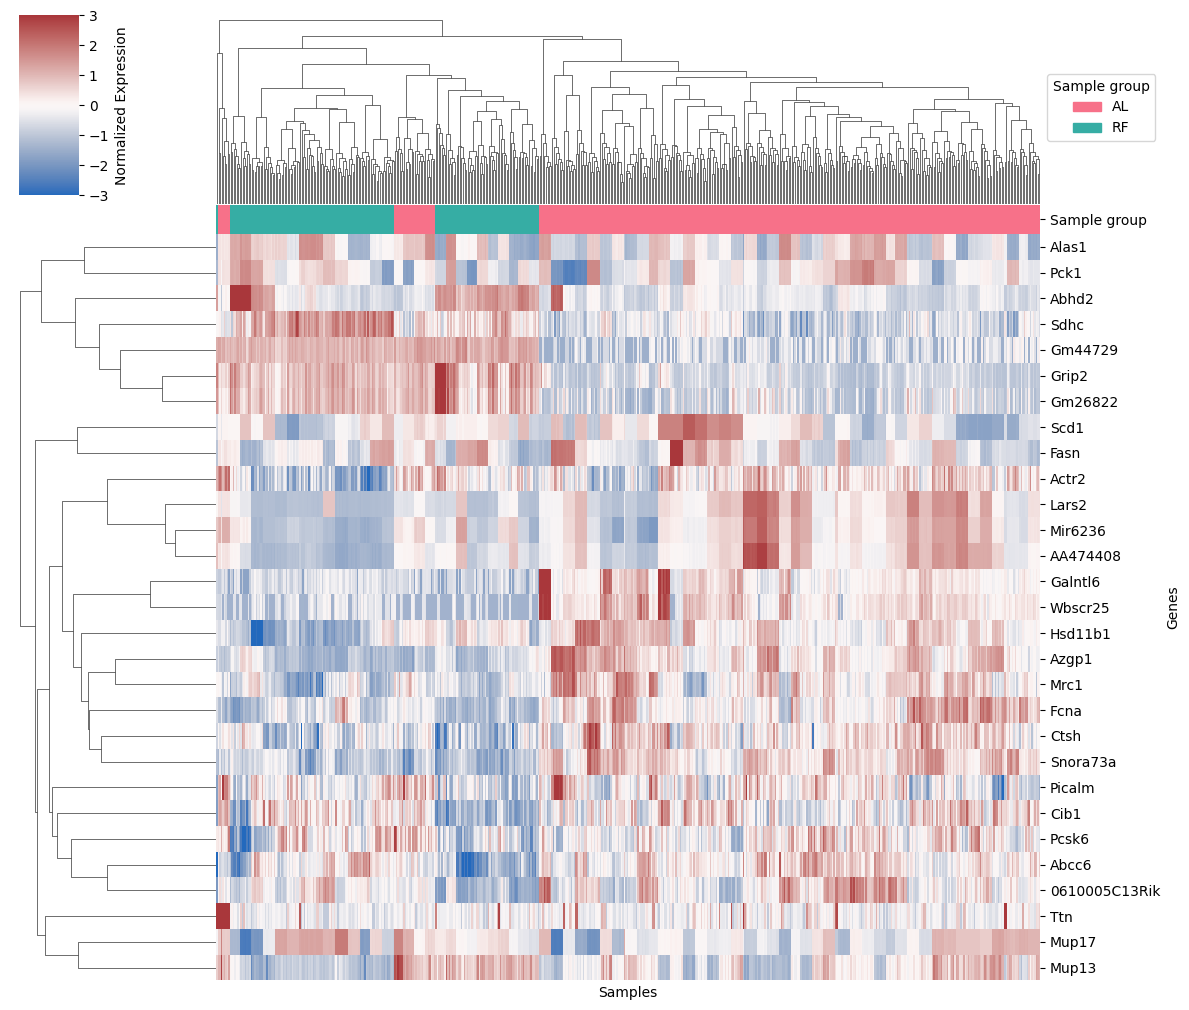

In [59]:
# Heatmap code:

RF_Genes = [3237, 1209, 814, 2601, 690, 2794, 212, 1350, 5, 1937]
LR_Genes = [2434, 469, 4221, 2467, 1070, 3322, 872, 950, 1110, 1076]
KNN_Genes = [6, 1, 11, 5, 15, 18, 4, 3, 0, 8]

relevant_genes = list(set(RF_Genes) | set(LR_Genes) | set(KNN_Genes))
relevant_gene_names = list(df["Gene"].iloc[relevant_genes])

expr = df.set_index("Gene")
expressions = expr.loc[relevant_gene_names, expr.columns]

annotations = pd.DataFrame({"Sample group": np.where(sample_groups, "AL", "RF")},
                            index=expressions.columns)

col_colors = pd.DataFrame(index=expressions.columns)
luts = {}
for name in annotations:
    cats = annotations[name].unique()
    luts[name] = dict(zip(cats, sns.color_palette("husl", len(cats))))
    col_colors[name] = annotations[name].map(luts[name])

g = sns.clustermap(expressions, z_score=0, cmap="vlag", center=0, vmin=-3, vmax=3, col_colors=col_colors,
                   xticklabels=False, yticklabels=True, figsize=(12,10), cbar_kws={"label": "Normalized Expression"})

g.ax_heatmap.set_xlabel("Samples")
g.ax_heatmap.set_ylabel("Genes")

handles = [Patch(color=c, label=l) for l, c in luts["Sample group"].items()]
g.ax_col_dendrogram.legend(handles=handles, title="Sample group", loc="center left", bbox_to_anchor=(1, 0.5))

g.savefig("results/assignment4/heatmap.png")